In [1]:
!pip install -q diffusers transformers accelerate lpips pandas matplotlib
import os
import torch
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from diffusers import StableDiffusionImg2ImgPipeline
import torchvision.transforms.functional as TF
import lpips

print("Phase 2 Environment and Dependencies Initialized.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.8/53.8 kB 1.7 MB/s eta 0:00:00


Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


Phase 2 Environment and Dependencies Initialized.


In [2]:
# 1. Dynamically locate the uploaded dataset in Kaggle's input directory
INPUT_BASE = None
for root, dirs, files in os.walk('/kaggle/input'):
    if 'pairs_manifest.csv' in files:
        INPUT_BASE = root
        break

if INPUT_BASE is None:
    raise FileNotFoundError("Could not find 'pairs_manifest.csv'. Check your uploaded dataset.")

print(f"Dataset located at: {INPUT_BASE}")

CSV_PATH = os.path.join(INPUT_BASE, 'pairs_manifest.csv')
ORIGINAL_DIR = os.path.join(INPUT_BASE, 'original')
PROTECTED_DIR = os.path.join(INPUT_BASE, 'protected')

# 2. Setup Output Directories for Download
PHASE2_DIR = '/kaggle/working/phase2_sd_verification'
P2_VISUALS = os.path.join(PHASE2_DIR, 'visual_comparisons')
P2_METRICS = os.path.join(PHASE2_DIR, 'metrics')
P2_RAW_OUT = os.path.join(PHASE2_DIR, 'raw_outputs')
os.makedirs(P2_VISUALS, exist_ok=True)
os.makedirs(P2_METRICS, exist_ok=True)
os.makedirs(P2_RAW_OUT, exist_ok=True)

# 3. Load Stable Diffusion v1.5 & LPIPS Evaluator
pipe = StableDiffusionImg2ImgPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5", 
    torch_dtype=torch.float16,
    safety_checker=None
).to("cuda")
pipe.set_progress_bar_config(disable=True)

vgg_eval = lpips.LPIPS(net='vgg').to('cuda')
print("Models loaded successfully into VRAM.")

Dataset located at: /kaggle/input/datasets/narainbk/phase2-matched-15pairs/phase2_matched_pairs


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

...

Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 206MB/s]


Loading model from: /usr/local/lib/python3.12/dist-packages/lpips/weights/v0.1/vgg.pth
Models loaded successfully into VRAM.


In [3]:
# Read the uploaded manifest
df = pd.read_csv(CSV_PATH)

# Simulate an attacker's prompt and Img2Img parameters
MALICIOUS_PROMPT = "a highly detailed portrait, cyberpunk style, neon lighting, digital art masterpiece"
STRENGTH = 0.55 
GUIDANCE_SCALE = 7.5
SEED = 2026

disruption_logs = []
print(f"Executing Deterministic Edits (Seed={SEED}, Strength={STRENGTH}) on {len(df)} Image Pairs...")

for idx, row in df.iterrows():
    pair_id = row['pair_id']
    clean_path = os.path.join(ORIGINAL_DIR, row['original_file'])
    prot_path = os.path.join(PROTECTED_DIR, row['protected_file'])
    
    clean_img = Image.open(clean_path).convert("RGB").resize((512, 512))
    prot_img = Image.open(prot_path).convert("RGB").resize((512, 512))
    
    # 1. Attacker Edits the CLEAN Image
    gen_clean = torch.Generator("cuda").manual_seed(SEED)
    edited_clean = pipe(prompt=MALICIOUS_PROMPT, image=clean_img, strength=STRENGTH, 
                        guidance_scale=GUIDANCE_SCALE, generator=gen_clean).images[0]
    
    # 2. Attacker Edits the PROTECTED Image
    gen_prot = torch.Generator("cuda").manual_seed(SEED)
    edited_prot = pipe(prompt=MALICIOUS_PROMPT, image=prot_img, strength=STRENGTH, 
                       guidance_scale=GUIDANCE_SCALE, generator=gen_prot).images[0]
    
    # Save raw generated outputs
    edited_clean.save(os.path.join(P2_RAW_OUT, f"{pair_id}_edited_original.png"))
    edited_prot.save(os.path.join(P2_RAW_OUT, f"{pair_id}_edited_protected.png"))
    
    # 3. Calculate Edit Disruption Score (LPIPS between outputs)
    t_ed_clean = TF.to_tensor(edited_clean).unsqueeze(0).to('cuda') * 2 - 1
    t_ed_prot = TF.to_tensor(edited_prot).unsqueeze(0).to('cuda') * 2 - 1
    
    with torch.no_grad():
        disruption_lpips = vgg_eval(t_ed_clean, t_ed_prot).item()
        
    disruption_logs.append({
        "Pair_ID": pair_id,
        "Original_File": row['original_file'],
        "Phase1_Injection_LPIPS": row['lpips'],
        "Phase2_Edit_Disruption_LPIPS": disruption_lpips
    })
    
    # 4. Generate 2x2 Panel-Ready Presentation Grid
    fig, axes = plt.subplots(2, 2, figsize=(10, 10))
    axes[0, 0].imshow(clean_img); axes[0, 0].set_title("1. Original Image", fontweight='bold'); axes[0, 0].axis('off')
    axes[0, 1].imshow(edited_clean); axes[0, 1].set_title("2. Successful Edit (Attacker Goal)", fontweight='bold'); axes[0, 1].axis('off')
    axes[1, 0].imshow(prot_img); axes[1, 0].set_title("3. DiffShield Protected Image", fontweight='bold'); axes[1, 0].axis('off')
    axes[1, 1].imshow(edited_prot); axes[1, 1].set_title(f"4. Disrupted Edit (LPIPS: {disruption_lpips:.3f})", color='red', fontweight='bold'); axes[1, 1].axis('off')
    
    plt.tight_layout()
    plt.savefig(os.path.join(P2_VISUALS, f"{pair_id}_panel_grid.png"), dpi=200, bbox_inches='tight')
    plt.close()
    
    print(f"Processed {pair_id} -> Edit Disruption LPIPS: {disruption_lpips:.4f}")

print("\nPhase 2 Inference Complete.")

Executing Deterministic Edits (Seed=2026, Strength=0.55) on 15 Image Pairs...
Processed pair_01 -> Edit Disruption LPIPS: 0.4626
Processed pair_02 -> Edit Disruption LPIPS: 0.4805
Processed pair_03 -> Edit Disruption LPIPS: 0.5089
Processed pair_04 -> Edit Disruption LPIPS: 0.4402
Processed pair_05 -> Edit Disruption LPIPS: 0.4700
Processed pair_06 -> Edit Disruption LPIPS: 0.4944
Processed pair_07 -> Edit Disruption LPIPS: 0.4066
Processed pair_08 -> Edit Disruption LPIPS: 0.4433
Processed pair_09 -> Edit Disruption LPIPS: 0.3807
Processed pair_10 -> Edit Disruption LPIPS: 0.5323
Processed pair_11 -> Edit Disruption LPIPS: 0.4954
Processed pair_12 -> Edit Disruption LPIPS: 0.4830
Processed pair_13 -> Edit Disruption LPIPS: 0.4387
Processed pair_14 -> Edit Disruption LPIPS: 0.4175
Processed pair_15 -> Edit Disruption LPIPS: 0.4472

Phase 2 Inference Complete.


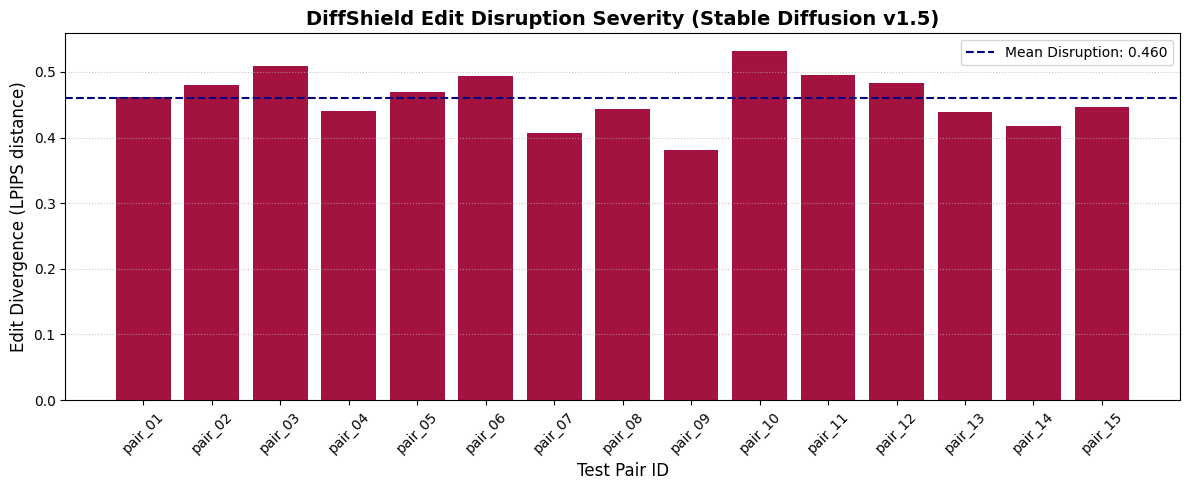

Mean Phase 2 Edit Disruption (LPIPS): 0.4601

Zipping Phase 2 results for download...
Success! Download 'diffshield_phase2_verification_results.zip' from the output panel.


In [4]:
# Save complete metric logs
disruption_df = pd.DataFrame(disruption_logs)
disruption_df.to_csv(os.path.join(P2_METRICS, 'phase2_disruption_metrics.csv'), index=False)

mean_disruption = disruption_df['Phase2_Edit_Disruption_LPIPS'].mean()

# Generate presentation bar chart
plt.figure(figsize=(12, 5))
bars = plt.bar(disruption_df['Pair_ID'], disruption_df['Phase2_Edit_Disruption_LPIPS'], color='#A4123F')
plt.axhline(y=mean_disruption, color='navy', linestyle='--', label=f'Mean Disruption: {mean_disruption:.3f}')
plt.title('DiffShield Edit Disruption Severity (Stable Diffusion v1.5)', fontsize=14, fontweight='bold')
plt.xlabel('Test Pair ID', fontsize=12)
plt.ylabel('Edit Divergence (LPIPS distance)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle=':', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(P2_METRICS, 'edit_disruption_barchart.png'), dpi=300, bbox_inches='tight')
plt.show()

print(f"Mean Phase 2 Edit Disruption (LPIPS): {mean_disruption:.4f}")
print("\nZipping Phase 2 results for download...")
!zip -r -q /kaggle/working/diffshield_phase2_verification_results.zip {PHASE2_DIR}
print("Success! Download 'diffshield_phase2_verification_results.zip' from the output panel.")